<a href="https://colab.research.google.com/github/Einstein71/sustainanble-forest-management/blob/main/Churn_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
df_1 = pd.read_excel("Bank_Churn_Messy.xlsx", sheet_name=None)

# Print the sheet names available in the file
print("Available sheets:", list(df_1.keys()))

# Accessing one of the valid sheets
account_df=df_1["Account_Info"]
customer_df=df_1["Customer_Info"]

Available sheets: ['Customer_Info', 'Account_Info']


In [3]:
account_df.head(2)

,CustomerId,Balance,NumOfProducts,HasCrCard,Tenure,IsActiveMember,Exited
0,15634602,€0.0,1,Yes,2,Yes,1
1,15634602,€0.0,1,Yes,2,Yes,1


In [4]:
customer_df.head(2)

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,EstimatedSalary
0,15634602,Hargrave,619,FRA,Female,42.0,2,€101348.88
1,15647311,Hill,608,Spain,Female,41.0,1,€112542.58


In [5]:
merged_df=customer_df.merge(account_df, how="left", on="CustomerId")
merged_df.head(2)

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure_x,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure_y,IsActiveMember,Exited
0,15634602,Hargrave,619,FRA,Female,42.0,2,€101348.88,€0.0,1,Yes,2,Yes,1
1,15634602,Hargrave,619,FRA,Female,42.0,2,€101348.88,€0.0,1,Yes,2,Yes,1


In [6]:
# Remove duplicate rows and assign back to merged_df
merged_df = merged_df.drop_duplicates()
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 0 to 10000
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10000 non-null  int64  
 1   Surname          9997 non-null   object 
 2   CreditScore      10000 non-null  int64  
 3   Geography        10000 non-null  object 
 4   Gender           10000 non-null  object 
 5   Age              9997 non-null   float64
 6   Tenure_x         10000 non-null  int64  
 7   EstimatedSalary  10000 non-null  object 
 8   Balance          10000 non-null  object 
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  object 
 11  Tenure_y         10000 non-null  int64  
 12  IsActiveMember   10000 non-null  object 
 13  Exited           10000 non-null  int64  
dtypes: float64(1), int64(6), object(7)
memory usage: 1.1+ MB


In [7]:
# Clean the currency symbol and convert to float
merged_df['EstimatedSalary'] = merged_df['EstimatedSalary'].astype(str).str.replace('€', '').astype(float)
merged_df['Balance'] = merged_df['Balance'].astype(str).str.replace('€', '').astype(float)
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 0 to 10000
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10000 non-null  int64  
 1   Surname          9997 non-null   object 
 2   CreditScore      10000 non-null  int64  
 3   Geography        10000 non-null  object 
 4   Gender           10000 non-null  object 
 5   Age              9997 non-null   float64
 6   Tenure_x         10000 non-null  int64  
 7   EstimatedSalary  10000 non-null  float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  object 
 11  Tenure_y         10000 non-null  int64  
 12  IsActiveMember   10000 non-null  object 
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(6), object(5)
memory usage: 1.1+ MB


In [8]:
# Use isna() within the query string to find missing values
merged_df.query("Surname.isna()").replace(" NaN", " Missing values")

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure_x,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure_y,IsActiveMember,Exited
29,15728693,NaN,574,Germany,Female,NaN,3,-999999.0,141349.43,1,Yes,3,Yes,0
122,15580203,NaN,674,Spain,Male,NaN,6,-999999.0,120193.42,1,No,6,No,0
9390,15756954,NaN,538,France,Female,NaN,2,-999999.0,0.00,1,Yes,2,Yes,0


In [9]:
import numpy as np

# 1. Replace the anomalous salary placeholder (-999999.0) with NaN (or you can use 0)
median_sal=merged_df["EstimatedSalary"].median()
merged_df['EstimatedSalary'] = merged_df['EstimatedSalary'].replace(-999999.0, median_sal)

# 2. Fill missing Surnames with a placeholder string
merged_df['Surname'] = merged_df['Surname'].fillna('Missing')

# 3. Fill missing Ages with the median age of the customers
median_age = merged_df['Age'].median()
merged_df['Age'] = merged_df['Age'].fillna(median_age)

# Display the previously anomalous rows to verify they are updated
display(merged_df.loc[[29, 122, 9390]])

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure_x,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure_y,IsActiveMember,Exited
29,15728693,Missing,574,Germany,Female,37.0,3,100191.725,141349.43,1,Yes,3,Yes,0
122,15580203,Missing,674,Spain,Male,37.0,6,100191.725,120193.42,1,No,6,No,0
9390,15756954,Missing,538,France,Female,37.0,2,100191.725,0.00,1,Yes,2,Yes,0


In [10]:
merged_df

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure_x,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure_y,IsActiveMember,Exited
0,15634602,Hargrave,619,FRA,Female,42.0,2,101348.88,0.00,1,Yes,2,Yes,1
2,15647311,Hill,608,Spain,Female,41.0,1,112542.58,83807.86,1,Yes,1,Yes,0
3,15619304,Onio,502,French,Female,42.0,8,113931.57,159660.80,3,No,8,No,1
4,15701354,Boni,699,FRA,Female,39.0,1,93826.63,0.00,2,No,1,No,0
5,15737888,Mitchell,850,Spain,Female,43.0,2,79084.10,125510.82,1,Yes,2,Yes,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9996,15606229,Obijiaku,771,France,Male,39.0,5,96270.64,0.00,2,No,5,No,0
9997,15569892,Johnstone,516,French,Male,35.0,10,101699.77,57369.61,1,Yes,10,Yes,0
9998,15584532,Liu,709,FRA,Female,36.0,7,42085.58,0.00,1,Yes,7,Yes,1
9999,15682355,Sabbatini,772,Germany,Male,42.0,3,92888.52,75075.31,2,No,3,No,1


In [11]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 0 to 10000
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10000 non-null  int64  
 1   Surname          10000 non-null  object 
 2   CreditScore      10000 non-null  int64  
 3   Geography        10000 non-null  object 
 4   Gender           10000 non-null  object 
 5   Age              10000 non-null  float64
 6   Tenure_x         10000 non-null  int64  
 7   EstimatedSalary  10000 non-null  float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  object 
 11  Tenure_y         10000 non-null  int64  
 12  IsActiveMember   10000 non-null  object 
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(6), object(5)
memory usage: 1.4+ MB


In [12]:
merged_df["Geography"]=merged_df["Geography"].replace("FRA", "France")
merged_df["Geography"]=merged_df["Geography"].replace("French", "France")
merged_df.query("Geography == 'Germany'")

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure_x,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure_y,IsActiveMember,Exited
8,15656148,Obinna,376,Germany,Female,29.0,4,119346.880,115046.74,4,No,4,No,1
16,15643966,Goforth,616,Germany,Male,45.0,3,64327.260,143129.41,2,Yes,3,Yes,0
17,15737452,Romeo,653,Germany,Male,58.0,1,5097.670,132602.88,1,No,1,No,1
27,15736816,Young,756,Germany,Male,36.0,2,170041.950,136815.64,1,Yes,2,Yes,0
29,15728693,Missing,574,Germany,Female,37.0,3,100191.725,141349.43,1,Yes,3,Yes,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9983,15768163,Griffin,655,Germany,Female,46.0,7,115146.400,137145.12,1,No,7,No,1
9985,15696175,Echezonachukwu,602,Germany,Male,35.0,7,51695.410,90602.42,2,Yes,7,Yes,0
9987,15581736,Bartlett,673,Germany,Male,47.0,1,34047.540,183579.54,2,Yes,1,Yes,0
9991,15798964,Nkemakonam,714,Germany,Male,33.0,3,53667.080,35016.60,1,No,3,No,0


In [13]:
exit_df=merged_df.groupby("Exited")["CustomerId"].count()

   Exited  Count
0       0   7963
1       1   2037


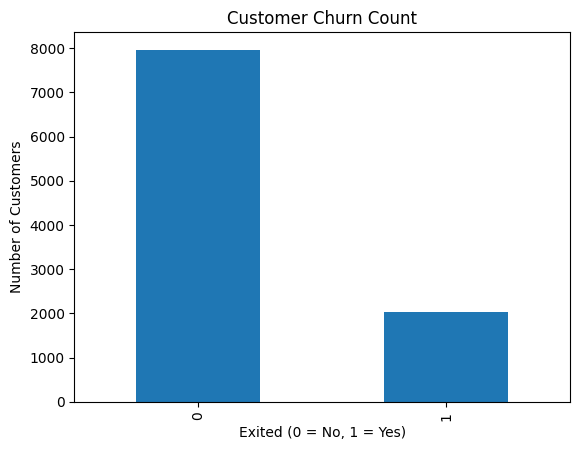

In [14]:
import matplotlib.pyplot as plt

# Option 1: Convert to a DataFrame by resetting the index if you need 'Exited' as a column
exit_df_clean = exit_df.reset_index(name="Count")
print(exit_df_clean)

# Option 2: Since 'Exited' is already the index, you can plot it directly
exit_df.plot(kind="bar")
plt.title("Customer Churn Count")
plt.xlabel("Exited (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

In [15]:
# Access index and values from the Series correctly
print(exit_df)
x_ax = exit_df.index
y_ax = exit_df.values # Use .values to get the counts

Exited
0    7963
1    2037
Name: CustomerId, dtype: int64


In [16]:
fil_df= merged_df[merged_df["Exited"]==1]
geo_df=fil_df.groupby("Geography")["Exited"].count()
geo_df

,Exited
Geography,
France,810
Germany,814
Spain,413


In [17]:
# 1. Convert the Series to a DataFrame
geo_df_calc = geo_df.reset_index(name="ChurntCount")

# 2. Add a calculated column (e.g., Percentage of overall churn)
total_churn = geo_df_calc["ChurntCount"].sum()
geo_df_calc["ChurnPercentage"] = (geo_df_calc["ChurntCount"] / total_churn) * 100

# Display the updated DataFrame
display(geo_df_calc)

,Geography,ChurntCount,ChurnPercentage
0,France,810,39.764359
1,Germany,814,39.960727
2,Spain,413,20.274914


In [18]:
gen_df=fil_df.groupby("Gender").agg({"Exited":"count"})
tol=gen_df["Exited"].sum()
gen_df["percentage"]=(gen_df["Exited"]/tol)*100

gen_df

,Exited,percentage
Gender,,
Female,1139,55.915562
Male,898,44.084438


In [19]:
merged_df.groupby("Geography").agg({"EstimatedSalary":"mean"
          , "Age":"mean","Balance":"mean", "Exited":"count" })

,EstimatedSalary,Age,Balance,Exited
Geography,,,,
France,99903.181848,38.512764,62092.636516,5014
Germany,101113.436813,39.769231,119730.116134,2509
Spain,99440.596817,38.890190,61818.147763,2477


In [20]:
merged_df.groupby("Gender").agg({"EstimatedSalary":"mean"
          , "Age":"mean","Balance":"mean", "Exited":"count" })

,EstimatedSalary,Age,Balance,Exited
Gender,,,,
Female,100605.958173,39.238169,75659.369139,4543
Male,99664.588068,38.657871,77173.974506,5457


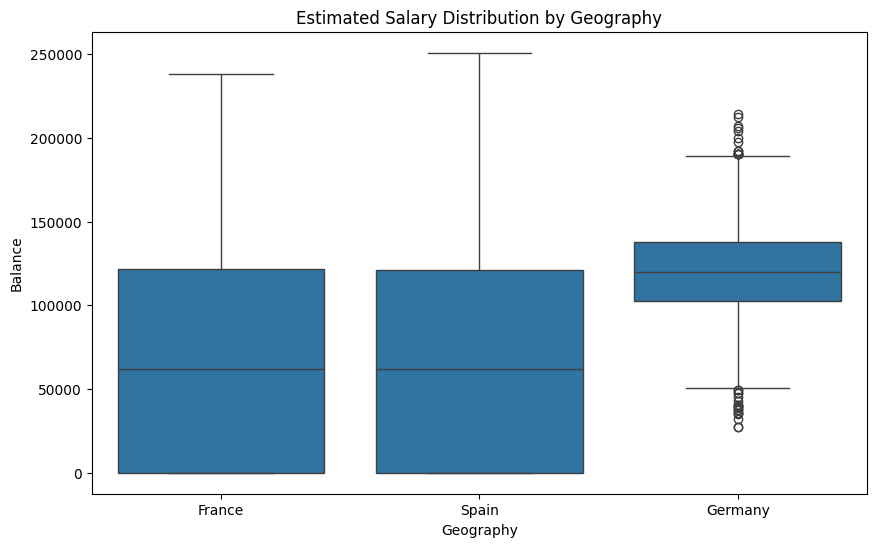

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set a larger figure size (e.g., width=10, height=6)
plt.figure(figsize=(10, 6))

# Draw boxplots using the raw merged_df to show full distribution
sns.boxplot(data=merged_df, x="Geography", y="Balance")

plt.title("Estimated Salary Distribution by Geography")
plt.show()

In [22]:
merged_df.query("Balance<50000 and Geography=='Germany'")

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure_x,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure_y,IsActiveMember,Exited
258,15592979,Rose,671,Germany,Female,34.0,6,156917.12,37266.67,2,No,6,No,0
369,15684042,Blair,636,Germany,Male,34.0,2,53512.16,40105.51,2,Yes,2,Yes,0
1182,15624428,Longo,651,Germany,Female,24.0,7,178341.33,40224.70,1,Yes,7,Yes,0
1580,15743976,Archer,618,Germany,Male,41.0,8,195775.48,37702.79,1,Yes,8,Yes,0
2223,15763662,Longo,711,Germany,Male,43.0,2,175423.69,39043.29,2,Yes,2,Yes,0
2593,15658956,Tuan,505,Germany,Male,40.0,6,155061.97,47869.69,2,Yes,6,Yes,0
3993,15602811,Chioke,730,Germany,Male,38.0,0,94003.11,38848.19,2,No,0,No,0
4569,15672875,Piccio,584,Germany,Male,32.0,8,137439.34,40172.91,1,Yes,8,Yes,0
4647,15665008,Sidorov,805,Germany,Female,26.0,8,28861.69,42712.87,2,Yes,8,Yes,0
5367,15812230,Elliot,670,Germany,Female,42.0,5,100324.01,49508.79,3,Yes,5,Yes,0


In [23]:
merged_df.groupby("Exited").agg({"EstimatedSalary":"mean",
                                 "Balance":"mean", "Age":"mean", "Gender":"count"})

,EstimatedSalary,Balance,Age,Gender
Exited,,,,
0,99740.919243,72745.296779,37.408012,7963
1,101465.677531,91108.539337,44.837997,2037


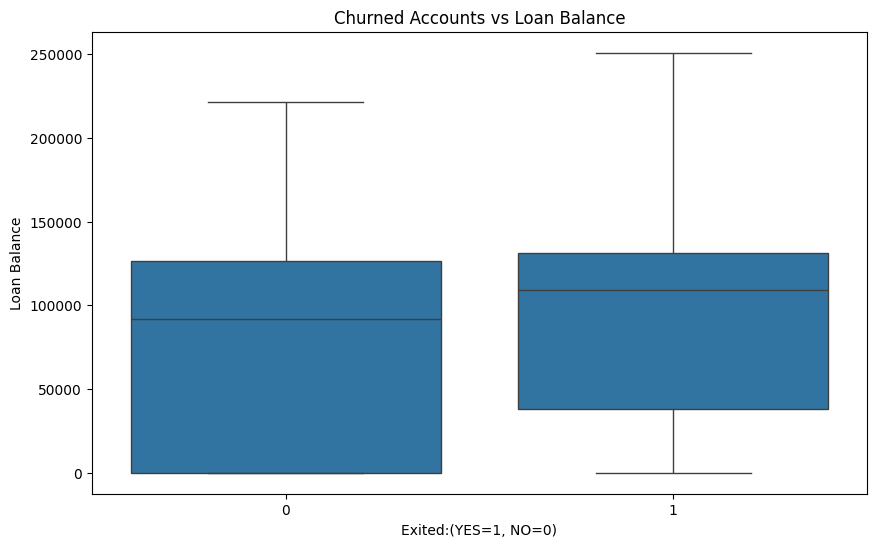

In [25]:
plt.figure(figsize=(10,6))
sns.boxplot(data=merged_df, x="Exited", y="Balance")
plt.ylabel("Loan Balance")
plt.xlabel("Exited:(YES=1, NO=0)")
plt.title("Churned Accounts vs Loan Balance")
plt.show()

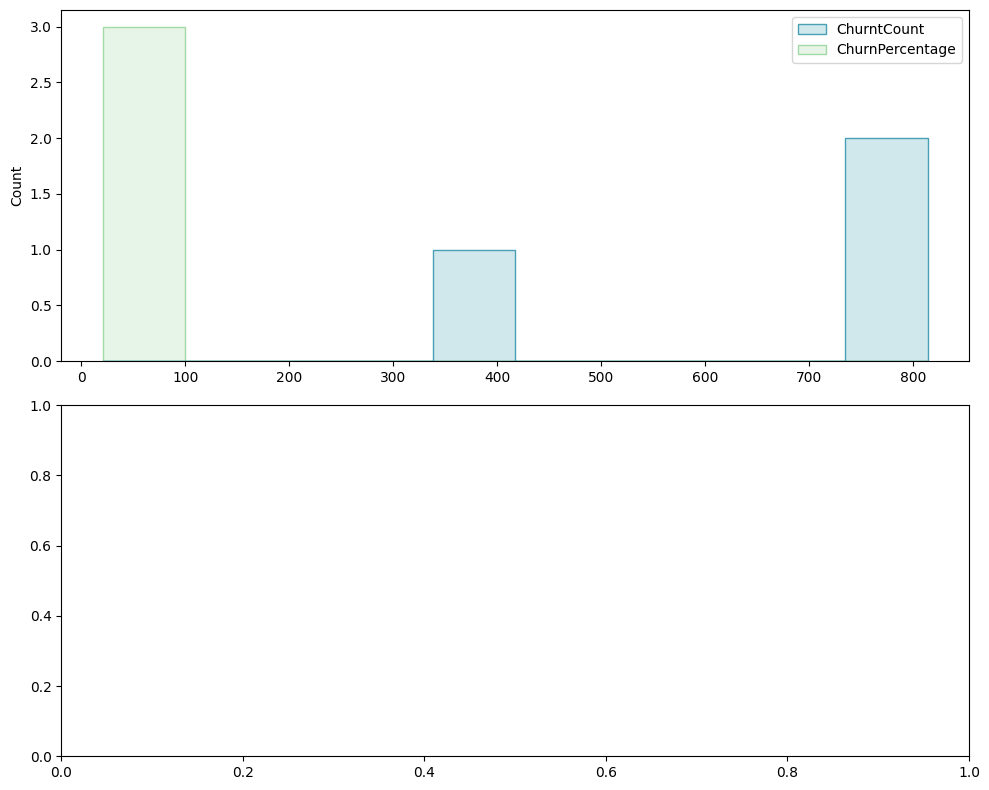

In [44]:

kde=True
sns.set_palette("Spectral_r", n_colors=6)
fig, ax=plt.subplots(2,1, figsize=(10,8))
sns.histplot(geo_df_calc, bins=10, element='step', ax=ax[0])
plt.tight_layout()
plt.show()